# Data statistics

Aggregate statistics of the edit table: which errors learners at each CEFR level make,
how many edits an essay has, and the mix of missing, replaced and unnecessary words.

The edit table (`data/processed/edits.jsonl`) is built from the BEA-2019 releases of
W&I+LOCNESS and FCE (see the README). It quotes learner sentences, so it stays local and
this notebook shows only counts and shares. The charts are saved to `report/figures/`
and are drawn by `scripts/make_report_assets.py`, which also runs without the notebook:

```bash
python scripts/make_report_assets.py data --edits data/processed/edits.jsonl
```

The same counts as tables are in `eval/results/data_stats.md`.

In [ ]:
import sys
from pathlib import Path

from explain_to_learn.edits import read_jsonl

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))  # the plotting code is in scripts/

In [ ]:
import make_report_assets as assets

FIGURES = ROOT / "report" / "figures"
edits = read_jsonl(ROOT / "data" / "processed" / "edits.jsonl")

## Error categories by level

Each column is one level and shows the share of that level's edits in each ERRANT error
category, so columns of different sizes can be compared. FCE essays have no individual
level and are all counted as B2, the level of the FCE exam; LOCNESS essays, written by
native speakers, are `native`.

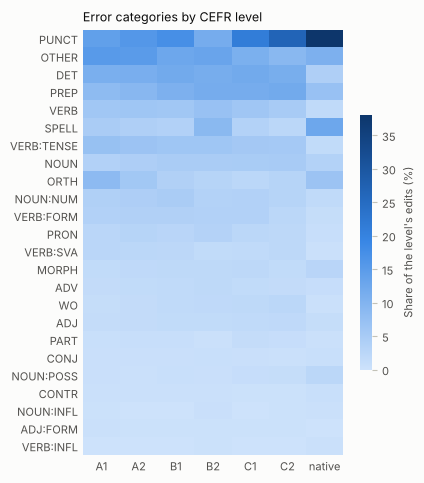

In [ ]:
assets.plot_category_heatmap(edits);

## Edits per essay by level

Essays without any edit are not in the edit table, so they are not counted here. The
number of edits also grows with essay length, which differs between tasks and levels.

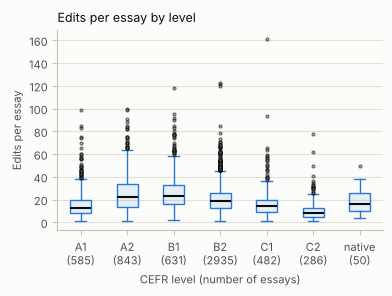

In [ ]:
assets.plot_edits_per_essay(edits);

## Operation mix by level

ERRANT labels each edit as a missing word (M), a replaced word (R) or an unnecessary
word (U).

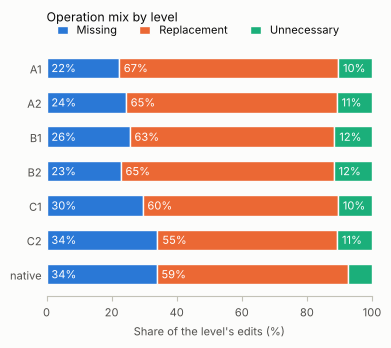

In [ ]:
assets.plot_operation_mix(edits);

## Most frequent categories per level

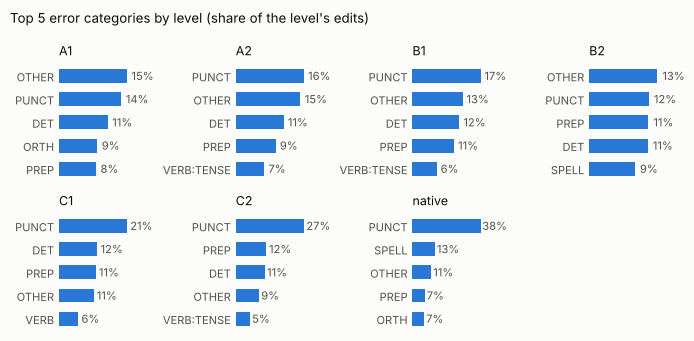

In [ ]:
assets.plot_top_categories(edits, n=5);

## W&I+LOCNESS only

In W&I every essay has its own CEFR rating, while all FCE essays count as B2. Without
FCE, the B2 column shows only individually rated essays. These charts are not saved.

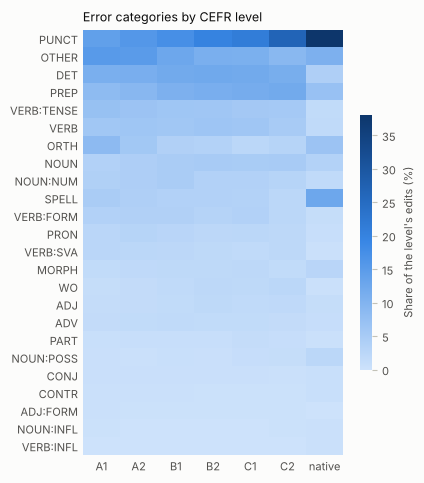

In [ ]:
rated = [edit for edit in edits if edit.corpus != "fce"]
assets.plot_category_heatmap(rated);

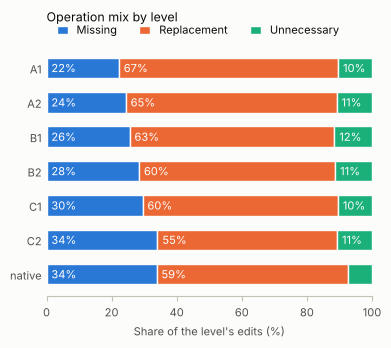

In [ ]:
assets.plot_operation_mix(rated);

## Save the report figures

In [ ]:
for path in assets.make_data_figures(edits, FIGURES):
    print(path.relative_to(ROOT))